In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from irregts import (
    structure_function,
    characteristic_timescale,
    dcf,
    calculate_dcf_centroid,
    bootstrap_dcf_significance,
    bootstrap_timescale_uncertainty,
    plot_combined_analysis,
    print_enhanced_timescale_report,
    print_dcf_binning_info,
    print_dcf_significance,
    print_dcf_peak_vs_centroid,
    save_sf_to_csv,
    save_dcf_to_csv
)

In [2]:
ngc5548_c5100 = pd.read_csv( 
                            "/home/arpan/project_root/sample_data/ngc5548/c5100.dat",
                            sep=r"\s+",
                            names=["mjd", "mag", "mag_err"],
                            header=None
                           )      
ngc5548_hbeta = pd.read_csv( 
                            "/home/arpan/project_root/sample_data/ngc5548/hbeta.dat",
                            sep=r"\s+",
                            names=["mjd", "mag", "mag_err"],
                            header=None
                           ) 

In [3]:
#Compute the structure function of narrow band H-beta and continuum band 5100 light curves
tau_hbeta, sf_hbeta, sf_hbeta_err, n_hbeta = structure_function(ngc5548_hbeta['mjd'], ngc5548_hbeta['mag'],
                                                                ngc5548_hbeta['mag_err'])

tau_c5100, sf_c5100, sf_c5100_err, n_c5100 = structure_function(ngc5548_c5100['mjd'], ngc5548_c5100['mag'], 
                                                                ngc5548_c5100['mag_err'] )

In [4]:
# --- Compute Discrete Correlation Function ---
lag_mid, dcf_vals, dcf_err, meta = dcf(
    ngc5548_hbeta['mjd'], ngc5548_hbeta['mag'], ngc5548_c5100['mjd'], ngc5548_c5100['mag'], ngc5548_hbeta['mag_err'], ngc5548_c5100['mag_err'] )


             IRREGULAR TIME SERIES ANALYSIS REPORT          

Structure Function Timescale Analysis [NGC5548 H-beta]
------------------------------------------------------------
  Characteristic Timescale : 1580.684 time units
  Bootstrap 1-σ Error Bar  : -327.892 / +826.242 (Median: 724.009)
------------------------------------------------------------

Structure Function Timescale Analysis [NGC5548 Continuum5100]
------------------------------------------------------------
  Characteristic Timescale : 1611.904 time units
  Bootstrap 1-σ Error Bar  : -666.622 / +34.922 (Median: 1584.852)
------------------------------------------------------------

DCF Lag Bin Configuration (Auto-Driven)
--------------------------------------------------
  Lag Search Range  : -1866.09 → 1866.09
  Bin Count         : 200
  Bin Width         : 18.66
  Nyquist Limit     : 2.10
  Cadence (t1 / t2) : 1.05 / 1.00
  Total Cross-Pairs : 1,931,904
--------------------------------------------------
-------------

/home/arpan/project_root/irregts/visualization.py:200: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


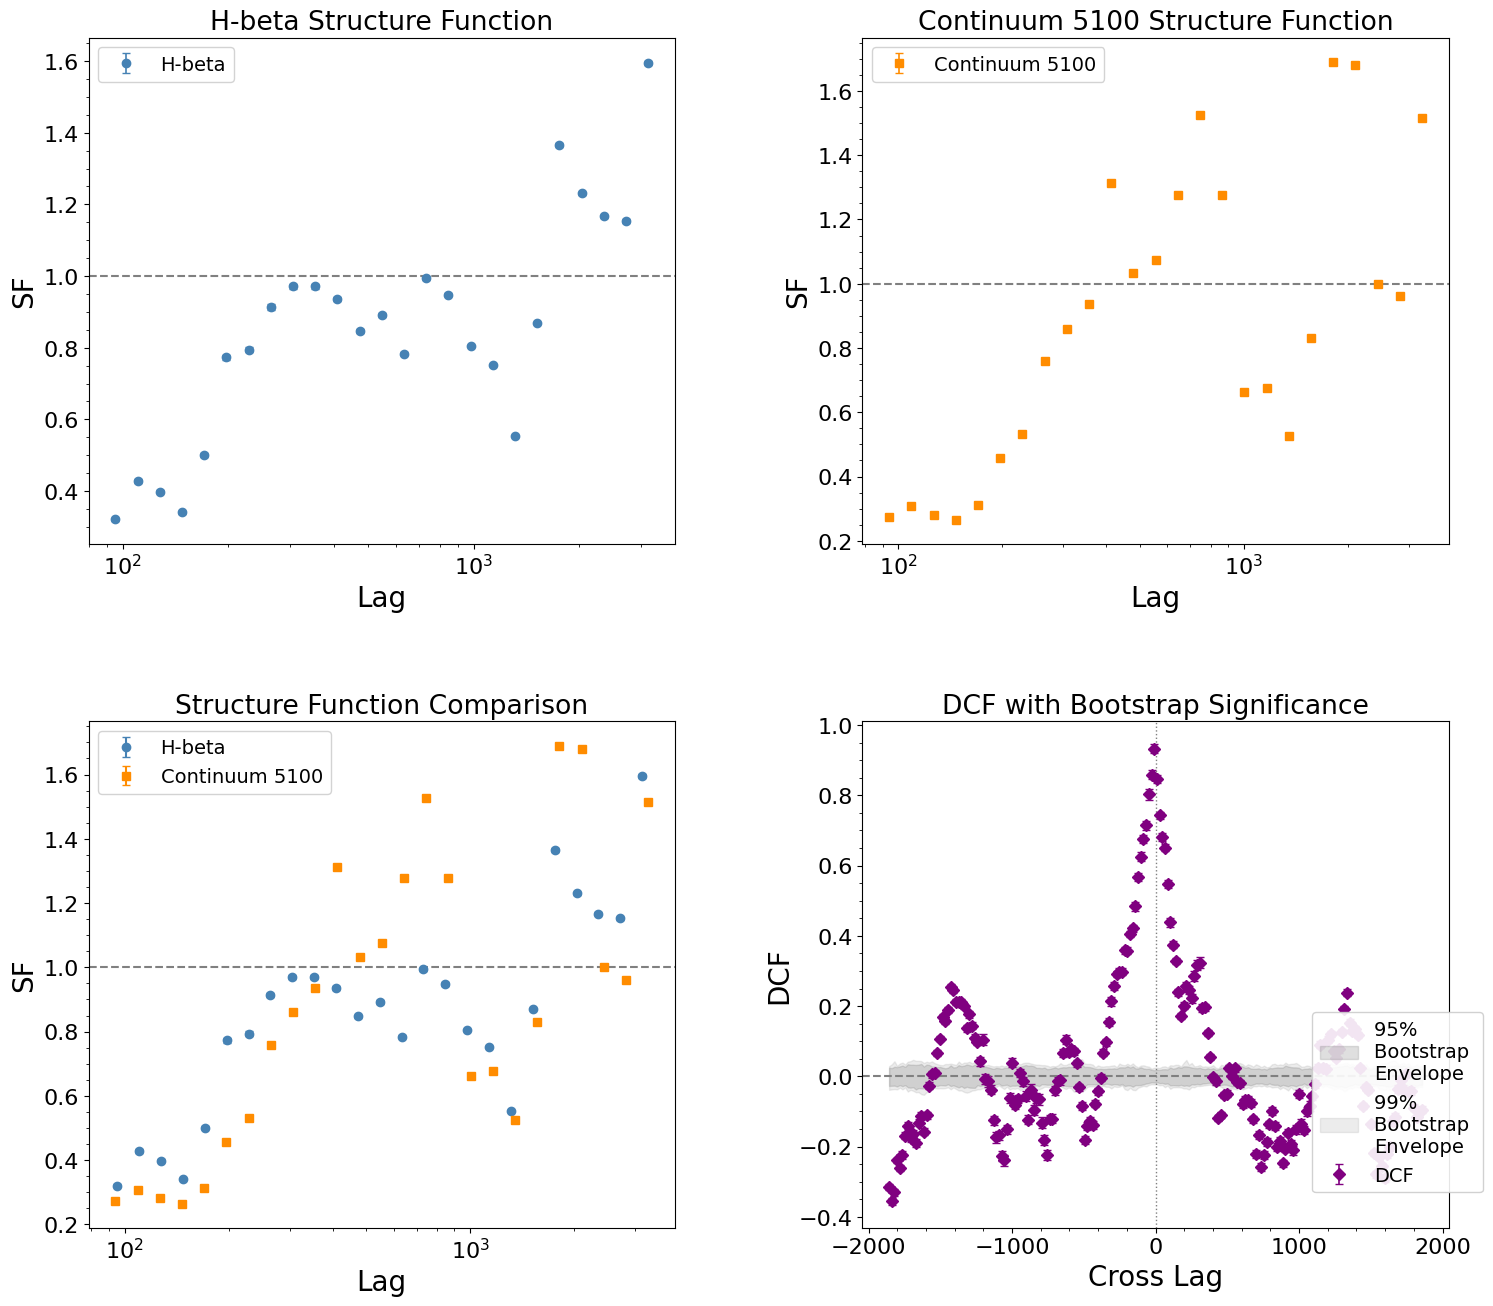

In [5]:
#--- 5. Bootstrap Loops ---
# A. DCF Significance Envelopes
p95, p99 = bootstrap_dcf_significance(
    ngc5548_hbeta['mjd'], ngc5548_hbeta['mag'],
    ngc5548_c5100['mjd'], ngc5548_c5100['mag'],
    ngc5548_hbeta['mag_err'], ngc5548_c5100['mag_err'] )

# B. Structure Function Characteristic Timescale Uncertainty (68% Confidence)
ts_med_ngc5548_hbeta, ts_low_ngc5548_hbeta, ts_up_ngc5548_hbeta = bootstrap_timescale_uncertainty(
    ngc5548_hbeta['mjd'], ngc5548_hbeta['mag'], err=ngc5548_hbeta['mag_err'], n_bins=None, n_boot=100 )
ts_med_ngc5548_c5100, ts_low_ngc5548_c5100, ts_up_ngc5548_c5100 = bootstrap_timescale_uncertainty(
    ngc5548_c5100['mjd'], ngc5548_c5100['mag'], err=ngc5548_c5100['mag_err'], n_bins=None, n_boot=100 )

# --- 6. Execute Enhanced Executive Reporting Dashboards ---
print("=" * 60)
print("             IRREGULAR TIME SERIES ANALYSIS REPORT          ")
print("=" * 60)

# A. Display detailed characteristic timescale constraints
print_enhanced_timescale_report("NGC5548 H-beta", ngc5548_hbeta['mjd'], ngc5548_hbeta['mag'],ngc5548_hbeta['mag_err'])
print_enhanced_timescale_report("NGC5548 Continuum5100", ngc5548_c5100['mjd'], ngc5548_c5100['mag'], ngc5548_c5100['mag_err'] )

# B. Evaluate whether the target lag is physically resolvable under Nyquist
print_dcf_binning_info(meta )

# C. Localization comparison: Absolute Peak vs. Flux-Weighted Centroid
print_dcf_peak_vs_centroid(lag_mid, dcf_vals)

# D. Threshold testing
print_dcf_significance(lag_mid, dcf_vals, p95, p99)


# --- 7. Reproducible CSV Data Serialization ---
print("\n[Data Serialization]")
save_sf_to_csv("NGC5548_H-beta_structure_function.csv", tau_hbeta, sf_hbeta, sf_hbeta_err, n_hbeta)
save_sf_to_csv("NGC5548_Cont5100_structure_function.csv", tau_c5100, sf_c5100, sf_c5100_err, n_c5100)
save_dcf_to_csv("NGC5548_H-beta_vs_Cont5100_correlation.csv", lag_mid, dcf_vals, dcf_err, p95=p95, p99=p99)


# --- 8. Render Visualizations with Bound Overlays ---
fig = plot_combined_analysis(
    tau_hbeta, sf_hbeta, sf_hbeta_err,
    tau_c5100, sf_c5100, sf_c5100_err,
    lag_mid, dcf_vals, dcf_err,
    label_a='H-beta',
    label_b='Continuum 5100',
    p95=p95,
    p99=p99
)

# Matplotlib automatically fits the vertical text elements without clipping margins
plt.show()